Columnas disponibles en el archivo: Index(['TCI', 'Genero', 'ID'], dtype='object')
        TCI Genero  ID
0  6.482347      M   1
1  0.926383      M   2
2  2.138911      F   3
3  6.169224      M   4
4  1.635379      M   5


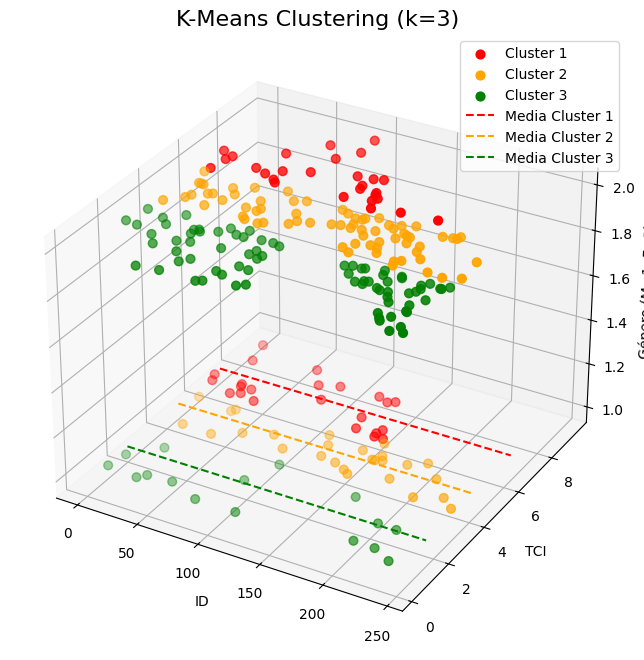

In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Cargar el archivo Excel
file_path = 'C:/Users/Marben/Desktop/DATASETSLIA/GDMKmedias.xlsx'  # Reemplaza con la ruta a tu archivo
df = pd.read_excel(file_path)

# Generar una columna 'ID' secuencialmente
df["ID"] = range(1, len(df) + 1)

# Verificar los nombres de las columnas
print("Columnas disponibles en el archivo:", df.columns)

# Renombrar columnas si es necesario
df.rename(columns={"nombre_actual_de_TCI": "TCI", "nombre_actual_de_Genero": "Genero"}, inplace=True)

# Verificar datos cargados
print(df.head())

# Preparar los datos para k-means (usando TCI como característica principal)
X = df[["TCI"]]

# Configurar y entrenar el modelo k-means
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kmeans.fit_predict(X)

# Obtener las medias de los clusters
cluster_means = df.groupby("Cluster")["TCI"].mean()

# Mapeo de colores para los puntos
color_map = {0: 'red', 1: 'orange', 2: 'green'}
df["Color"] = df["Cluster"].map(color_map)

# Graficar en 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Asignar colores según cluster y género en eje Z
z_map = {"M": 1, "F": 2}
df["Z"] = df["Genero"].map(z_map)

for cluster, color in color_map.items():
    cluster_data = df[df["Cluster"] == cluster]
    ax.scatter(
        cluster_data["ID"],
        cluster_data["TCI"],
        cluster_data["Z"],
        c=color,
        label=f'Cluster {cluster + 1}',
        s=40
    )

# Agregar líneas horizontales indicando la media de cada cluster
for cluster, mean in cluster_means.items():
    ax.plot(
        [0, df["ID"].max()],  # Línea en todo el eje X
        [mean, mean],         # Fija en la media
        [1, 1],               # Nivel Z base
        color=color_map[cluster],
        linestyle='--',
        linewidth=1.5,
        label=f'Media Cluster {cluster + 1}'
    )

# Configuración del gráfico
ax.set_title("K-Means Clustering (k=3)", fontsize=16)
ax.set_xlabel("ID")
ax.set_ylabel("TCI")
ax.set_zlabel("Género (M=1, F=2)")
ax.legend()
plt.show()
